## Домашнее задание

Как найти стог сена в иголке? Практический проект по построению системы поиска аномалий.


### Цель:

В этом домашнем задании вам предстоит настроить систему по поиску аномалий в банковских транзакциях. Мало того, что аномальных значений в данных меньше одного процента, так еще и переменные анонимизированные и представляют собой первые 28 главных компонент, полученных после PCA преобразования оригинальных данных (о которых мы ничего не знаем).


Смогут ли бравые unsupervised методы справиться с такой задачей? Можно ли работать в таких условиях? Кто подставил кролика Роджера? Ответы на некоторые их этих вопросов вы узнаете после выполнения задания :)



### Описание/Пошаговая инструкция выполнения домашнего задания:

1. Скачайте датасет с https://www.kaggle.com/mlg-ulb/creditcardfraud#creditcard.csv

2. Проведите небольшой EDA (гистограммы и описательные статистики - обязательно).

3. Воспользуйтесь процентом аномалий, подсчитанным по переменной Class, как "экспертной оценкой" загрязненности нашего датасета.

4. Попробуйте построить различные модели и алгоритмы, разобранные на занятии, используя полученную экспертную оценку для настройки параметров.

5. Воспользуйтесь стандартными методами оценки качества бинарной классификации (особенно хорошо подойдёт classification report и confusion matrix), и, используя предсказания моделей и переменную Class, проверьте, действительно ли модели справляются со своей задачей и насколько хорошо они это делают.

6. При помощи tSNE и/или UMAP, постройте сжатое представление исходных данных и проверьте, действительно ли аномалии лежат достаточно далеко от основной массы точек.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

import math

## 1. Скачайте датасет с https://www.kaggle.com/mlg-ulb/creditcardfraud#creditcard.csv

In [2]:
df = pd.read_csv('creditcard.csv')

In [3]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 2. Проведите небольшой EDA (гистограммы и описательные статистики - обязательно).

In [4]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [5]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [7]:
data = df[df.columns.drop('Time')]
data.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


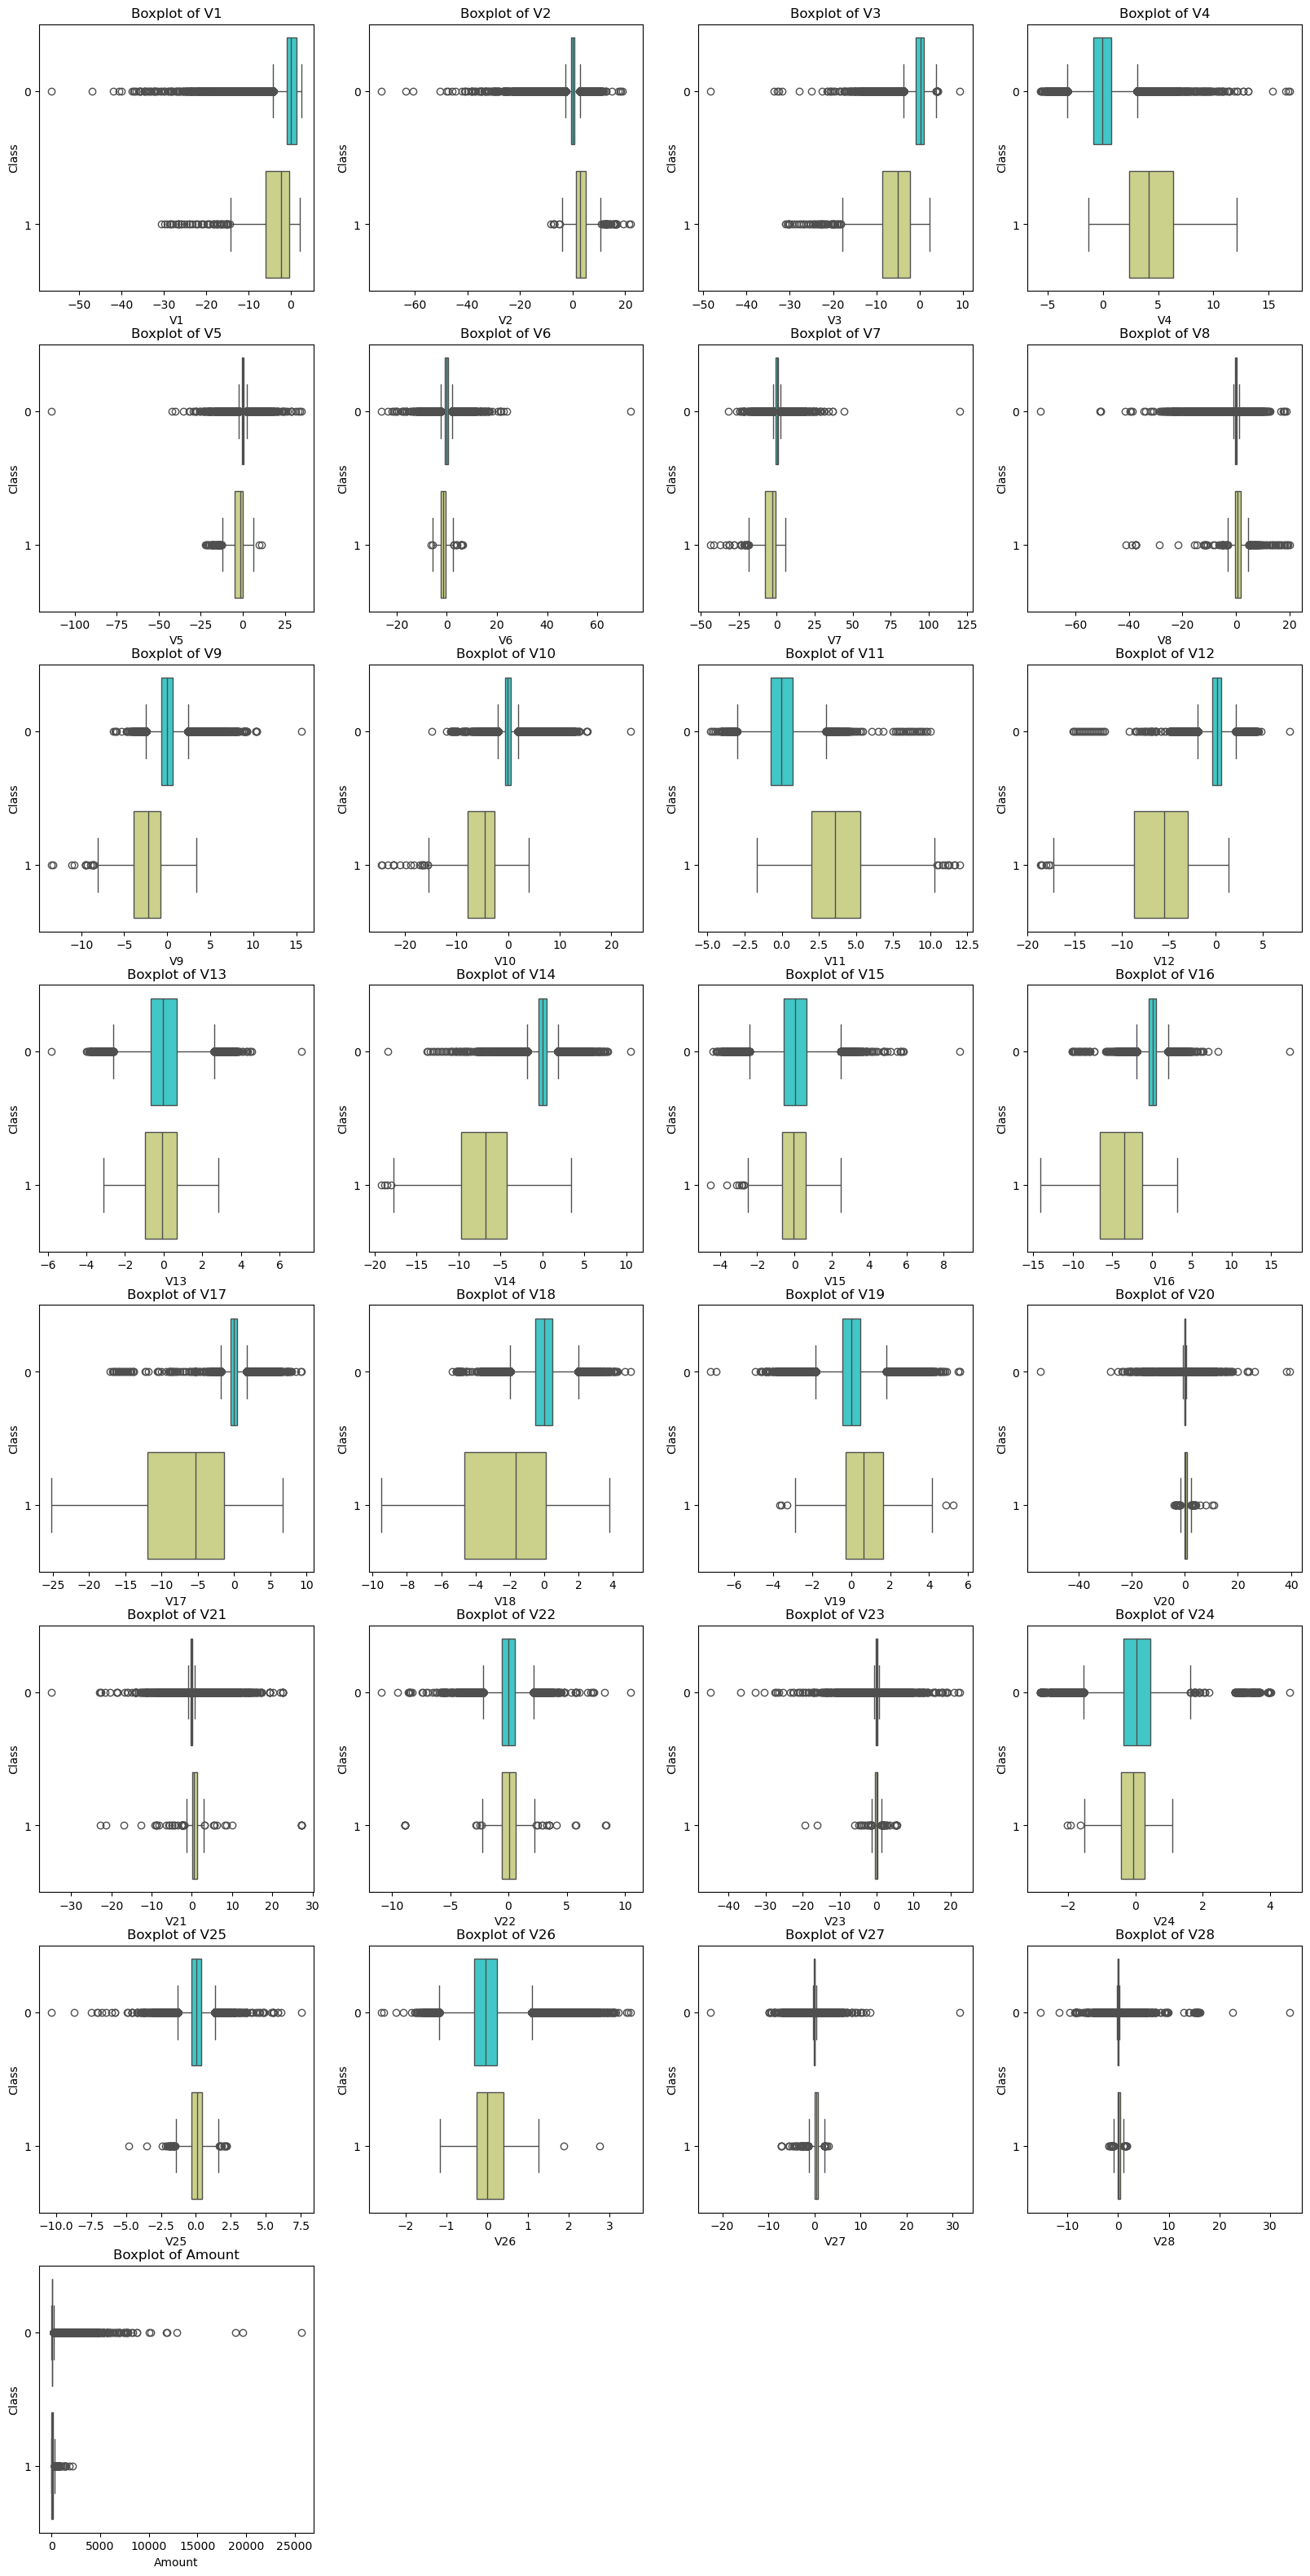

In [8]:
ncols = 4
elements_number = len(data.columns.drop('Class'))
nrows = math.ceil(elements_number/ncols)
figure, axis = plt.subplots( nrows, ncols, figsize=(20, 40))
axis = axis.flatten()
for i, col in enumerate(data[data.columns.drop('Class')]):
   sns.boxplot(ax=axis[i],x=data[col],y = data['Class'], palette='rainbow', orient = 'h')
   axis[i].set_title(f'Boxplot of {col}')
for i in range(elements_number,len(axis)): axis[i].remove()

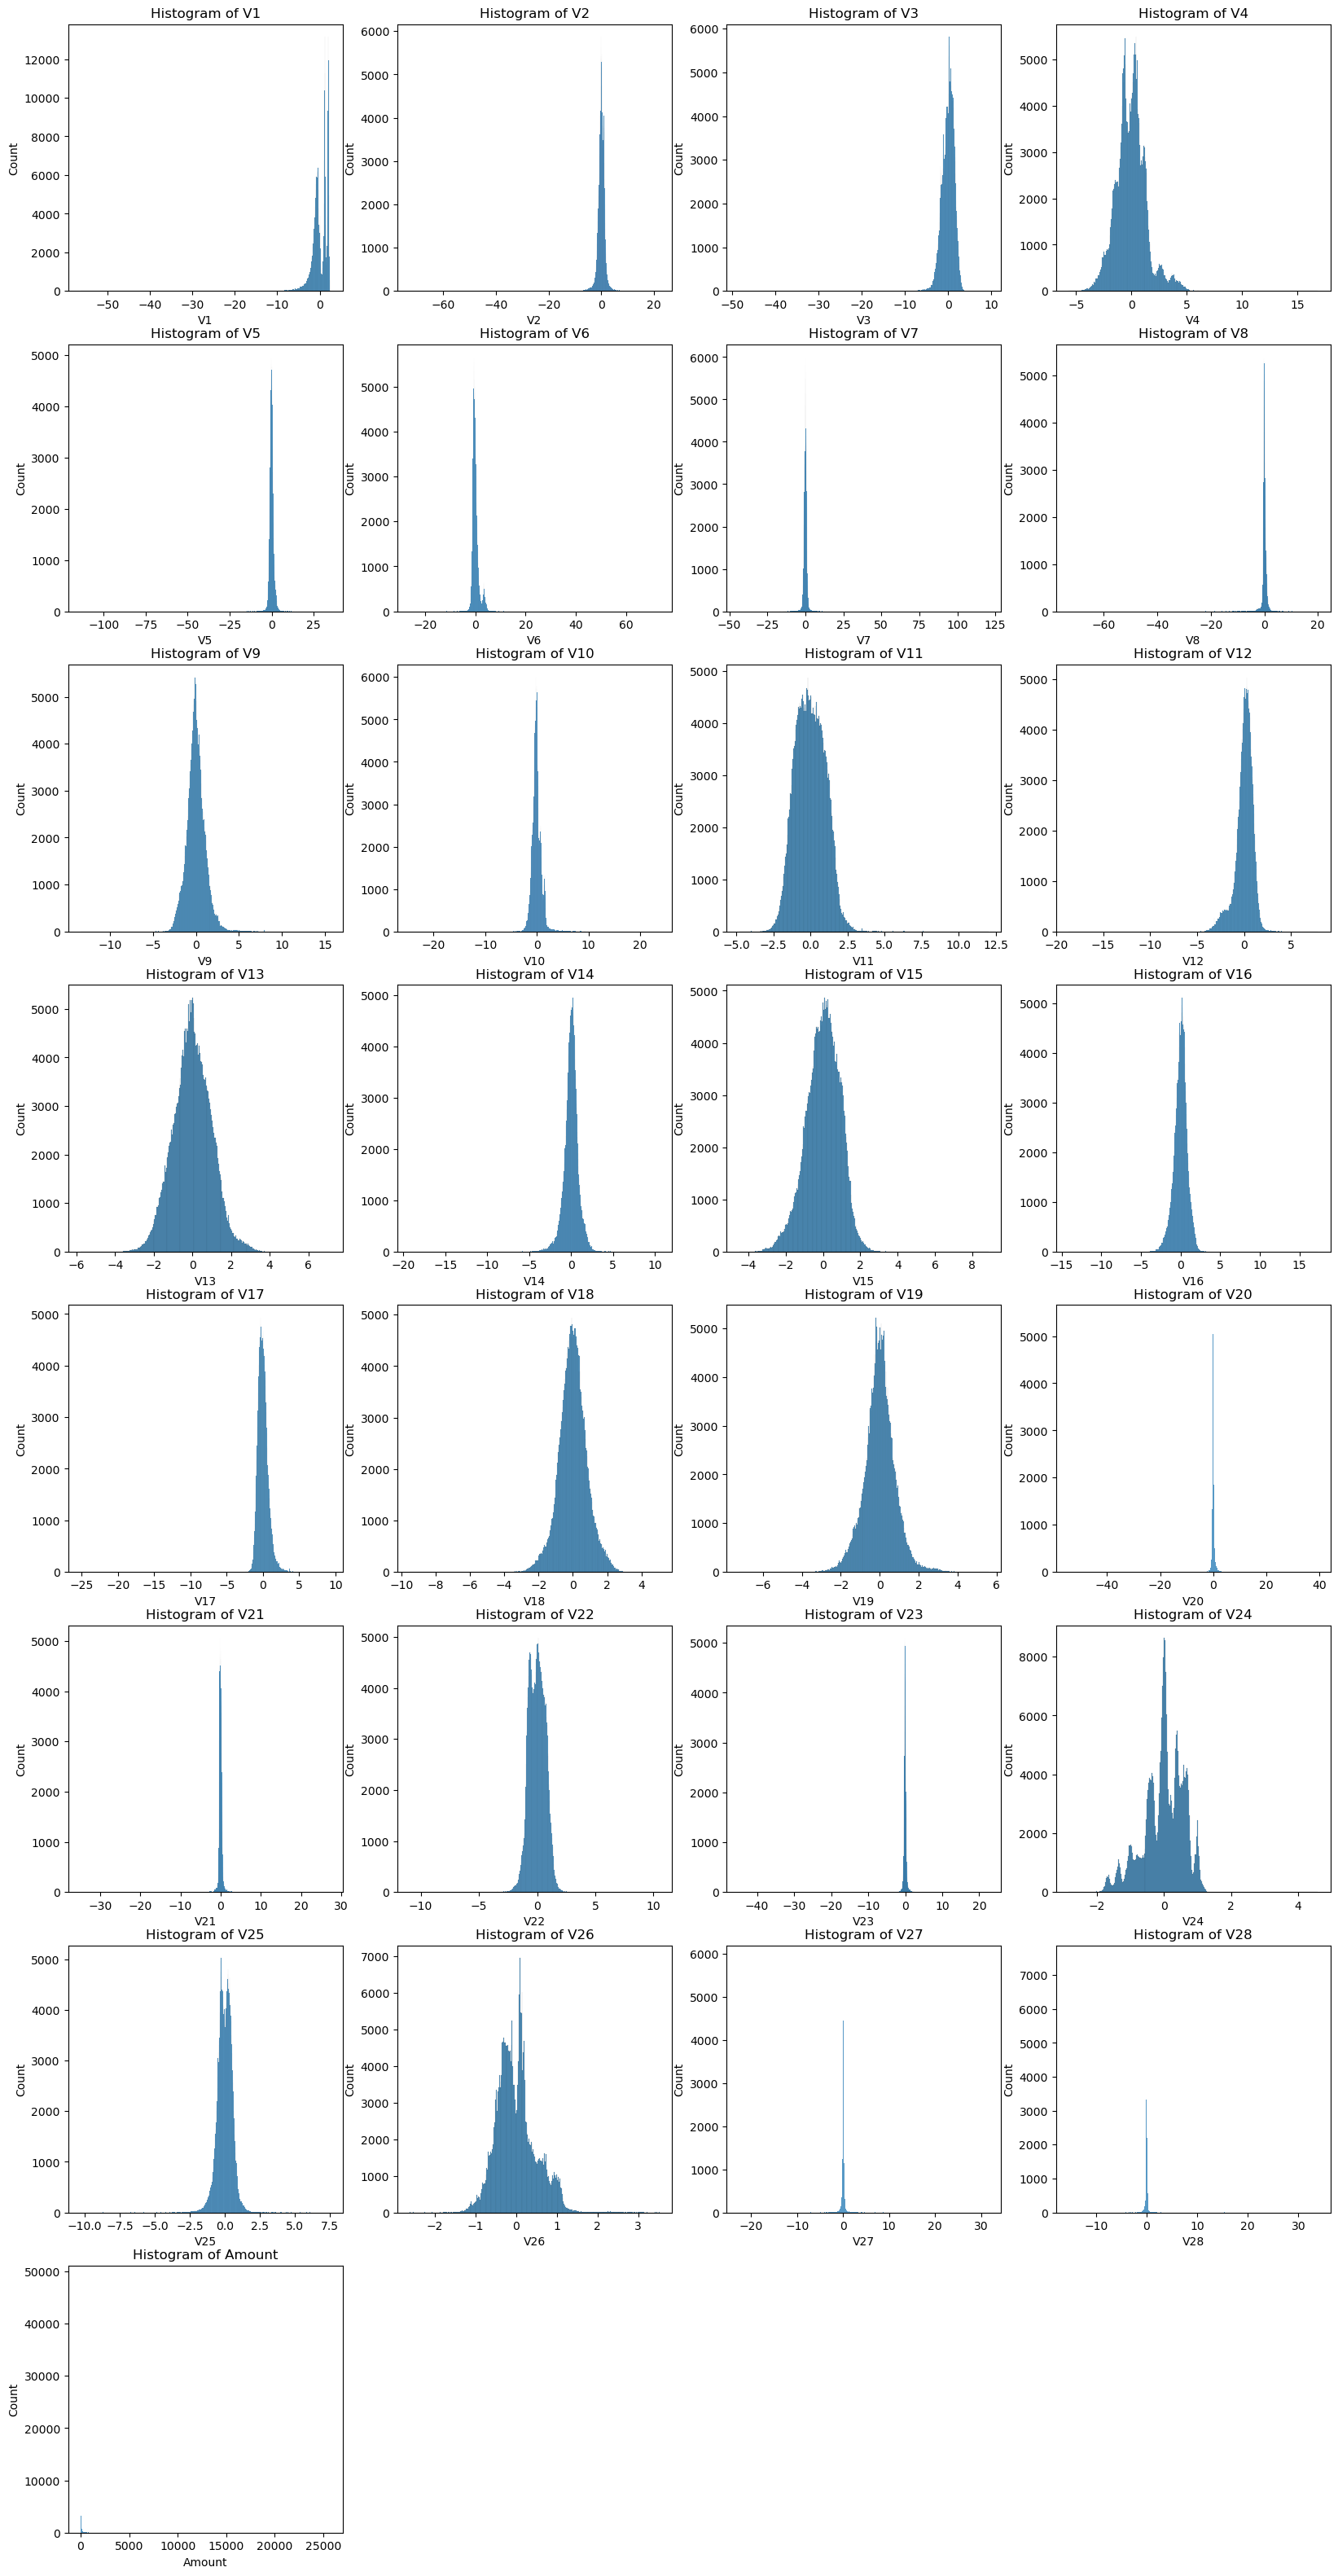

In [9]:
ncols = 4
elements_number = len(data.columns.drop('Class'))
nrows = math.ceil(elements_number/ncols)
figure, axis = plt.subplots( nrows, ncols, figsize=(20, 40))
axis = axis.flatten()
for i, col in enumerate(data[data.columns.drop('Class')]):
   sns.histplot(ax=axis[i],x=data[col])
   axis[i].set_title(f'Histogram of {col}')
for i in range(elements_number,len(axis)): axis[i].remove()

<Axes: >

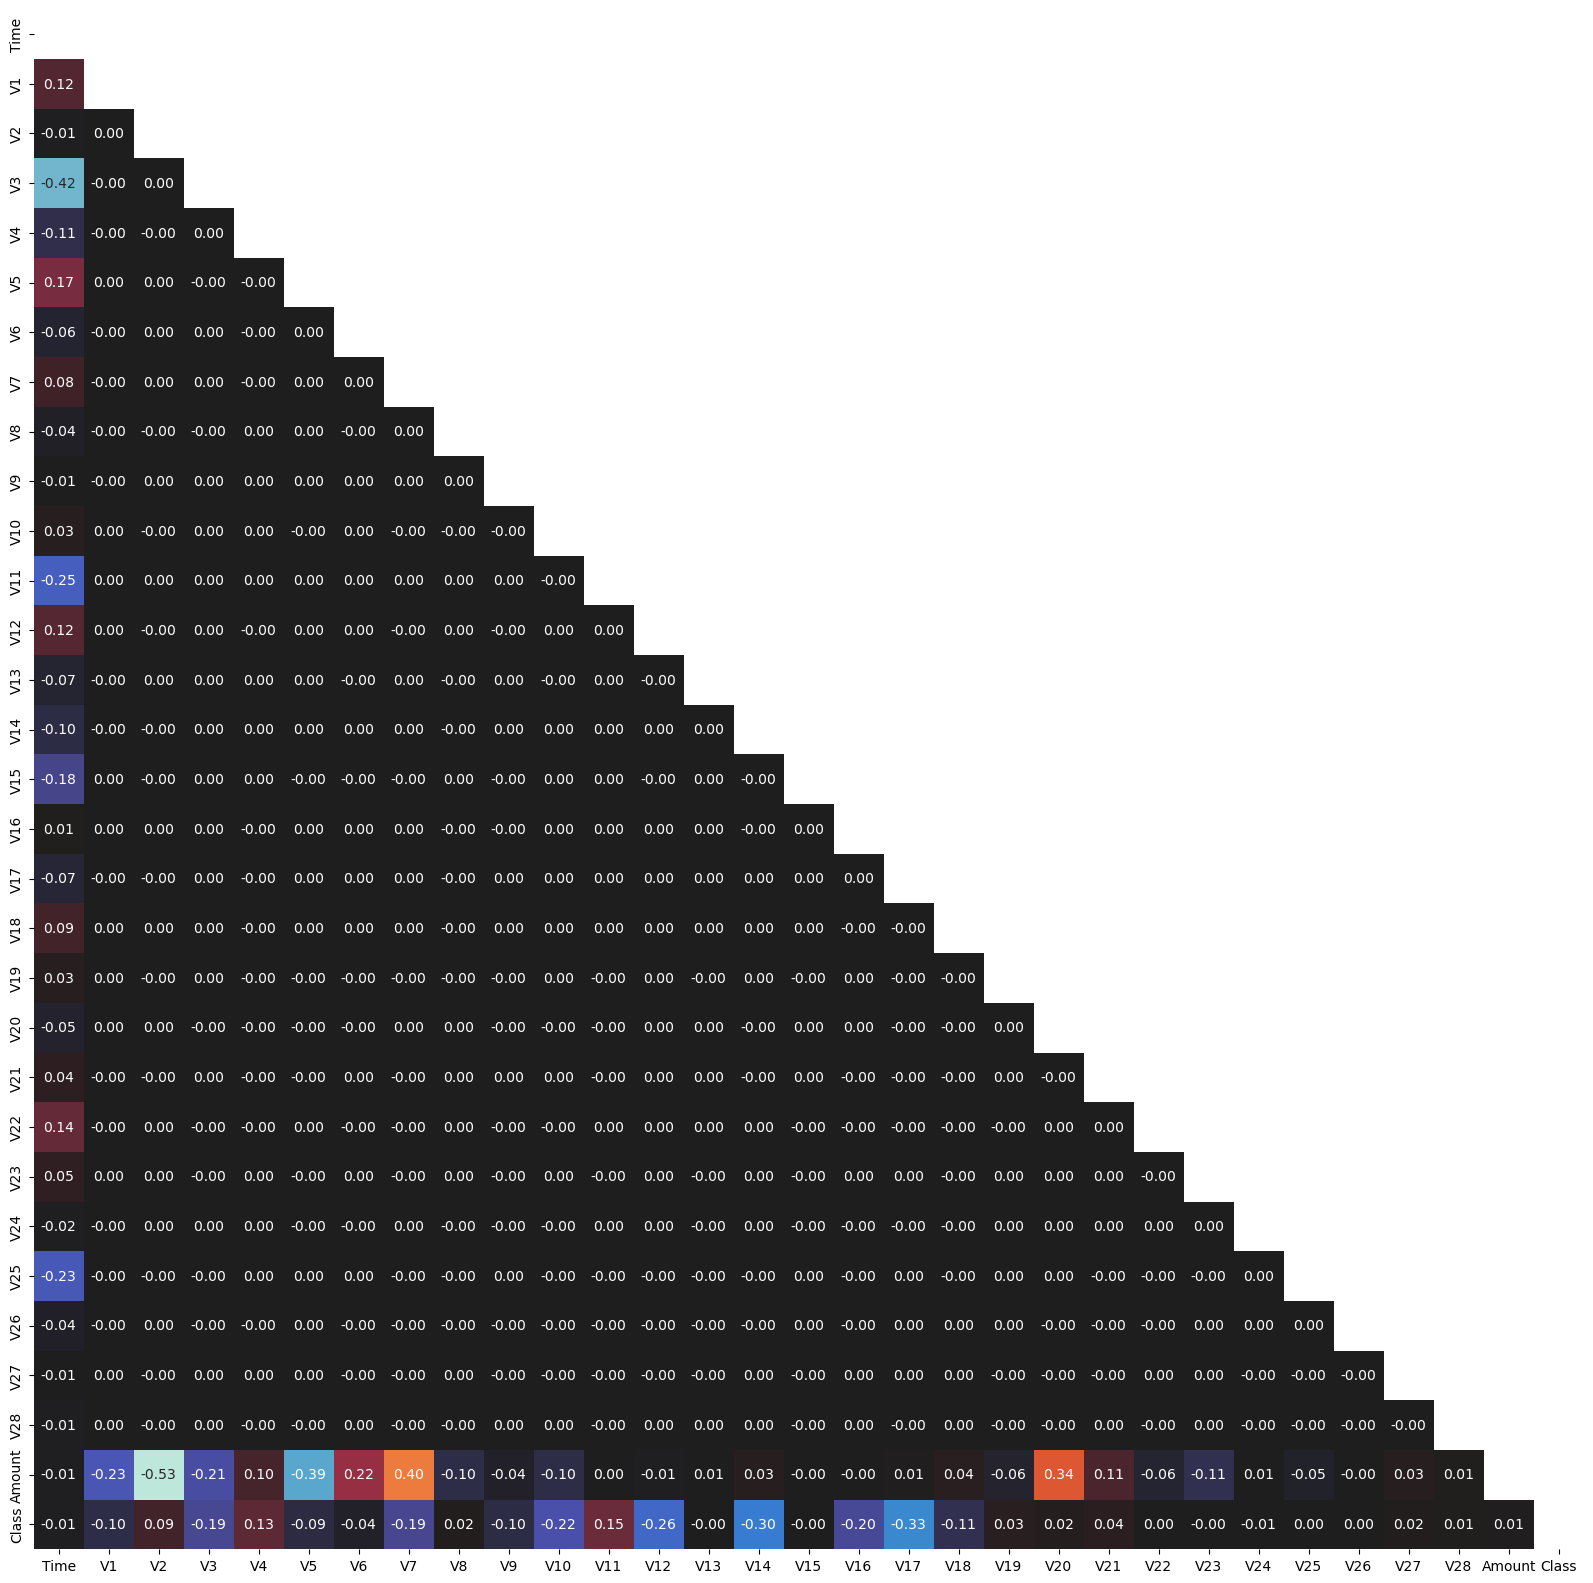

In [10]:
corr_matrix = df.corr()
lower = corr_matrix.where(np.tril(np.ones(corr_matrix.shape), k=-1).astype(bool))

fig, ax = plt.subplots(figsize=(20,20))
sns.heatmap(lower, annot=True, fmt='.2f', cbar=False, center=0, ax=ax)

## 3. Воспользуйтесь процентом аномалий, подсчитанным по переменной Class, как "экспертной оценкой" загрязненности нашего датасета.

In [11]:
anomal_perc = df[df['Class']==1].shape[0]/df.shape[0]
anomal_perc

0.001727485630620034

## 4. Попробуйте построить различные модели и алгоритмы, разобранные на занятии, используя полученную экспертную оценку для настройки параметров.

Масштабируем данные

In [12]:
data_features = df[df.columns.drop(['Time','Class'])].copy()
data_features.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99


Используем логарифмическое преобразование для асимметричных данных. Это позволит убрать хвосты, которые смещают оценки статистических методов, а также cнизить разреженность данных.

In [13]:
def log_transform_skewed(column):
    transformed = np.where(column >= 0, np.log1p(column), -np.log1p(-column))
    return transformed

data_scaled = data_features.copy()

for col in data_features.columns:
    data_scaled[col] = log_transform_skewed(data_features[col])

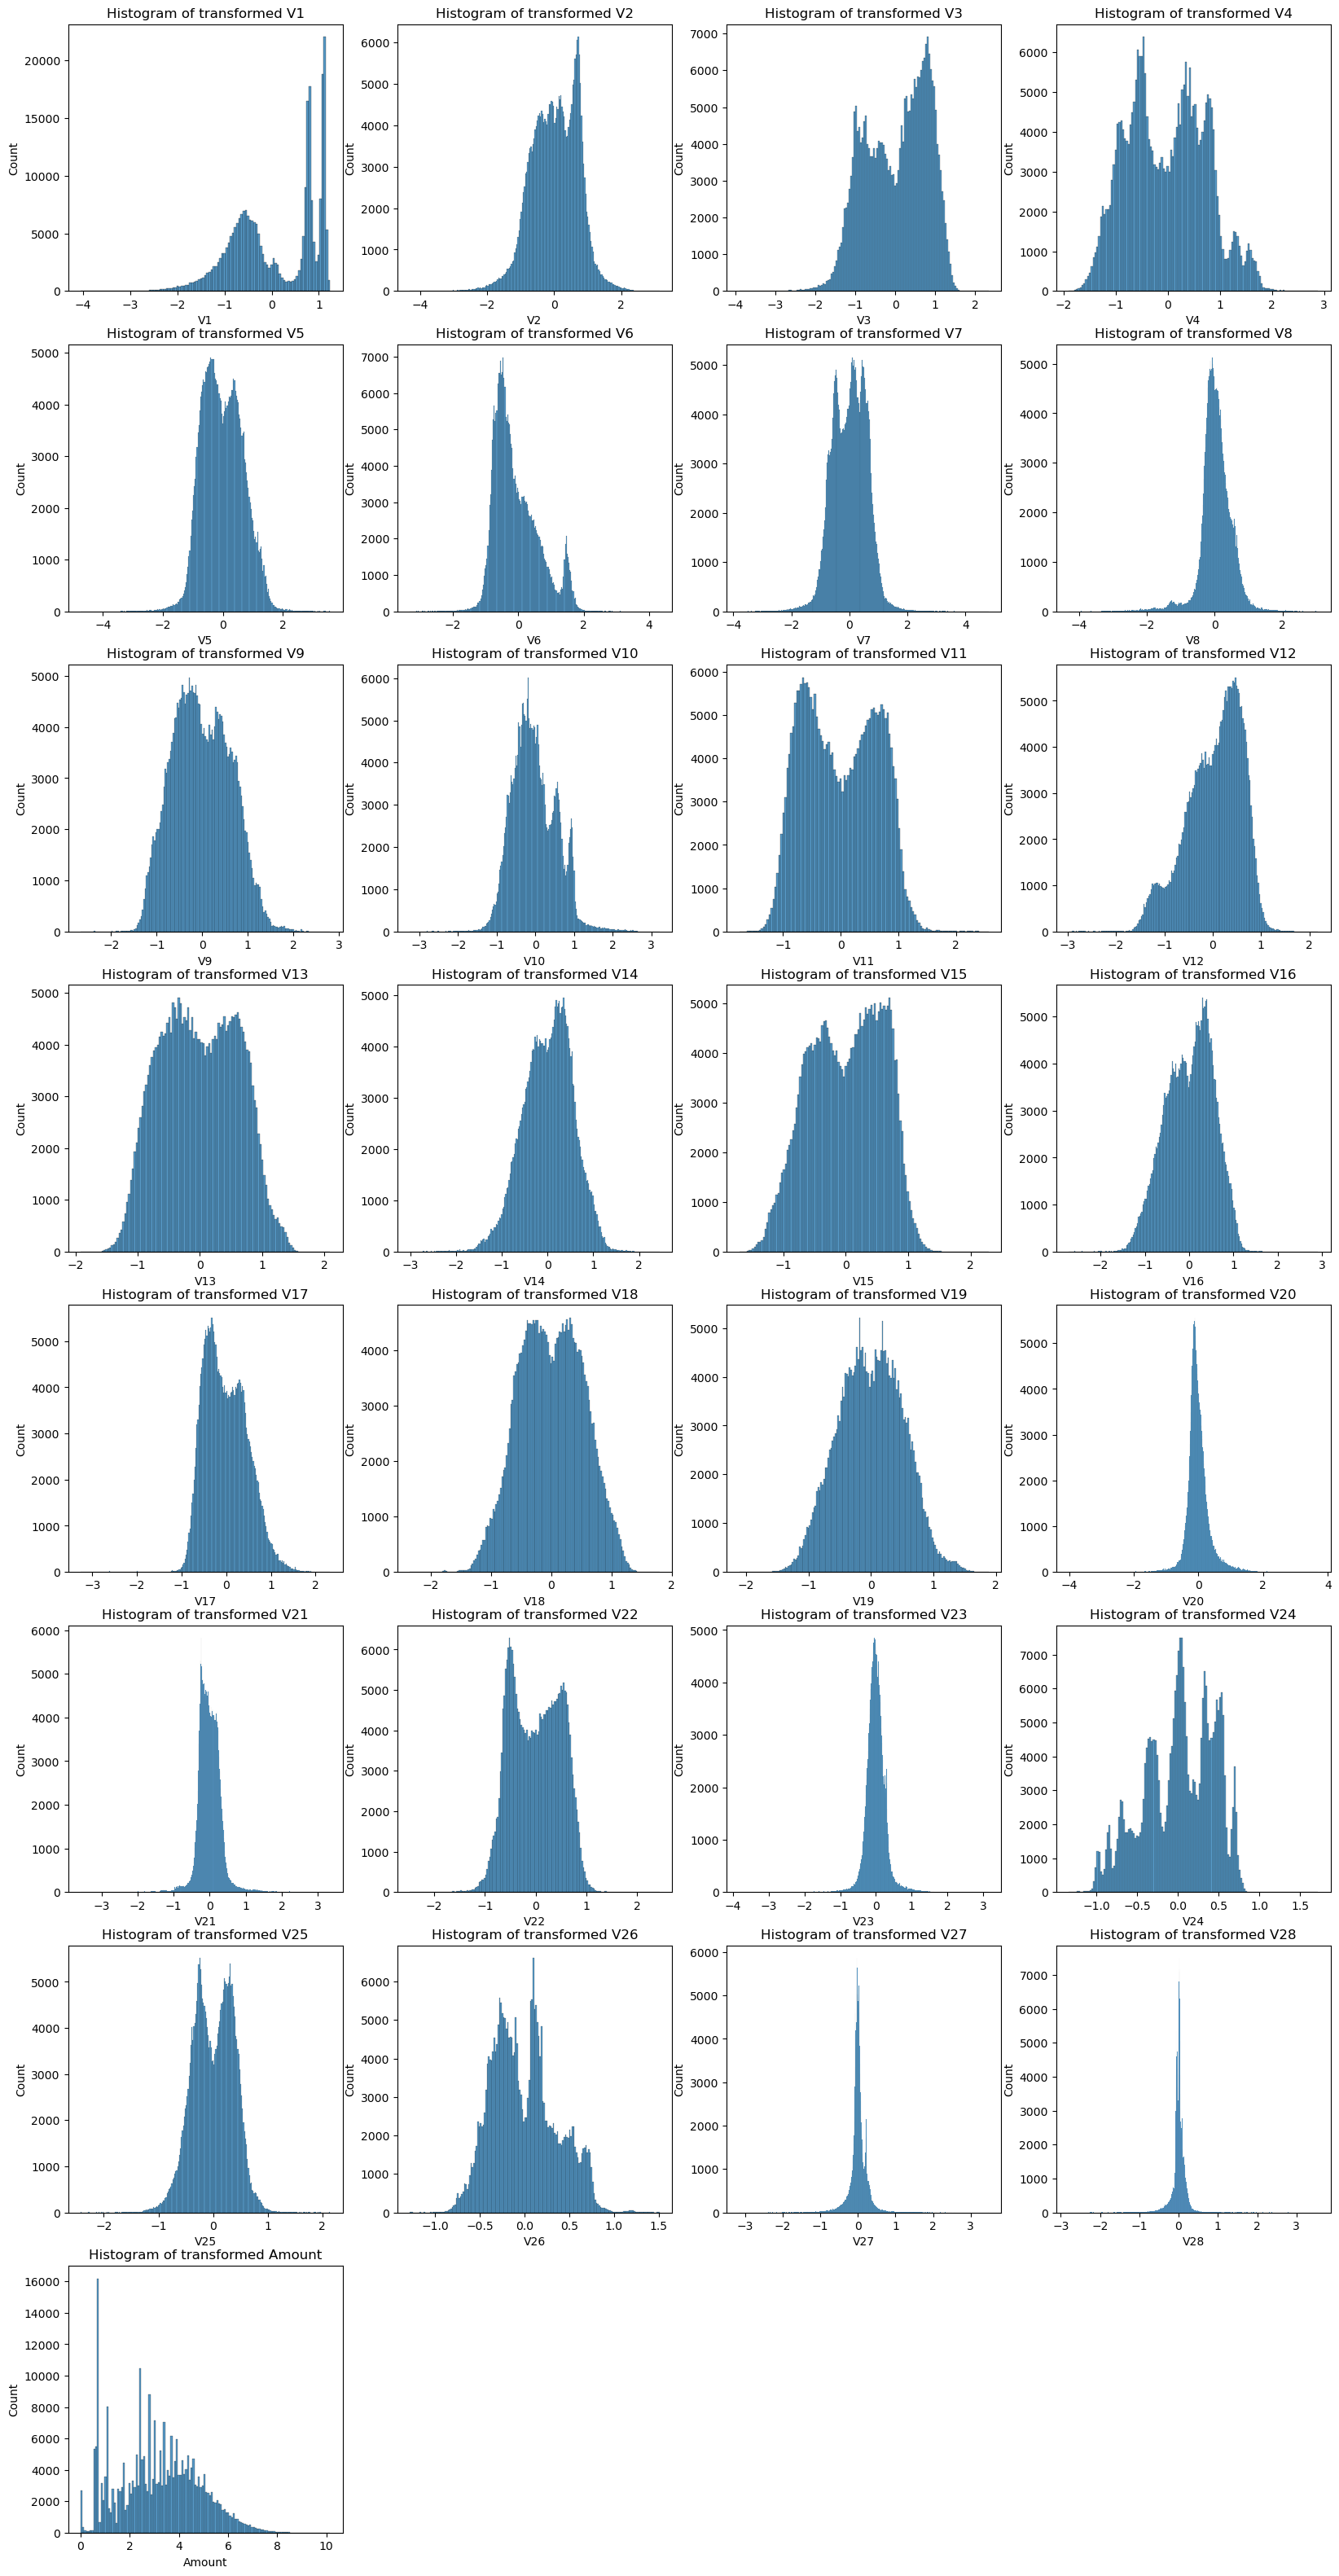

In [14]:
data = data_scaled
ncols = 4
elements_number = len(data.columns)
nrows = math.ceil(elements_number/ncols)
figure, axis = plt.subplots( nrows, ncols, figsize=(20, 40))
axis = axis.flatten()
for i, col in enumerate(data):
   sns.histplot(ax=axis[i],x=data[col])
   axis[i].set_title(f'Histogram of transformed {col}')
for i in range(elements_number,len(axis)): axis[i].remove()

In [15]:
data_scaled.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
0,-0.858580,-0.070255,1.263094,0.866325,-0.291416,0.380071,0.214788,0.094126,0.310265,0.086906,...,0.224273,-0.018141,0.245169,-0.104787,0.064784,0.120924,-0.173209,0.125362,-0.020835,5.014760
1,0.784749,0.235981,0.153991,0.370290,0.058286,-0.079145,-0.075852,0.081674,-0.227474,-0.154414,...,-0.066801,-0.203573,-0.493886,0.096480,-0.292555,0.154582,0.118578,-0.008943,0.014617,1.305626
2,-0.857964,-0.850221,1.020005,0.321924,-0.407595,1.029798,0.583031,0.221282,-0.922135,0.188670,...,0.421981,0.221541,0.571928,0.646795,-0.524303,-0.283404,-0.130235,-0.053875,-0.058035,5.939276
3,-0.676139,-0.169933,1.027114,-0.622344,-0.010256,0.809686,0.213181,0.320224,-0.870047,-0.053495,...,-0.188997,-0.102828,0.005260,-0.174223,-0.777293,0.499184,-0.200431,0.060834,0.059643,4.824306
4,-0.769290,0.630067,0.935590,0.338637,-0.341597,0.091596,0.465582,-0.239436,0.597594,0.561371,...,0.342555,-0.009387,0.586830,-0.128796,0.132139,-0.187317,0.406992,0.198377,0.194870,4.262539


In [16]:
def anomalies_report(outliers):
    print("Total number of outliers: {}\nPercentage of outliers:   {:.2f}%".format(
            sum(outliers), 100*sum(outliers)/len(outliers)))

## 3-сигмы

In [17]:
def outlier_std(data, col, threshold=3):
    mean = data[col].mean()
    std = data[col].std()
    up_bound = mean + threshold * std
    low_bound = mean - threshold * std
    anomalies = pd.concat([data[col]>up_bound, data[col]<low_bound], axis=1).any(axis = 1)
    return anomalies, up_bound, low_bound

def get_column_outliers(data, columns=None, function=outlier_std, threshold=3):
    if columns:
        columns_to_check = columns
    else:
        columns_to_check = data.columns

    outliers = pd.Series(data=[False]*len(data), index=data_features.index, name='is_outlier')
    comparison_table = {}
    for column in columns_to_check:
        anomalies, upper_bound, lower_bound = function(data, column, threshold=threshold)
        comparison_table[column] = [upper_bound, lower_bound, sum(anomalies), 100*sum(anomalies)/len(anomalies)]
        outliers[anomalies[anomalies].index] = True

    comparison_table = pd.DataFrame(comparison_table).T
    comparison_table.columns=['upper_bound', 'lower_bound', 'anomalies_count', 'anomalies_percentage']
    comparison_table = comparison_table.sort_values(by='anomalies_percentage', ascending=False)

    return comparison_table, outliers

In [18]:
comparison_table, std_outliers = get_column_outliers(data_scaled)
anomalies_report(std_outliers)

Total number of outliers: 21116
Percentage of outliers:   7.41%


In [19]:
comparison_table

,upper_bound,lower_bound,anomalies_count,anomalies_percentage
V20,1.072889,-1.099332,6222.0,2.184637
V27,0.719291,-0.709750,6186.0,2.171997
V28,0.551221,-0.545940,5681.0,1.994684
V8,1.437603,-1.372950,5321.0,1.868283
V23,0.884418,-0.887217,5309.0,1.864069
V21,0.997758,-1.017005,5289.0,1.857047
V10,1.686878,-1.736337,2113.0,0.741906
V7,1.775424,-1.760995,1984.0,0.696612
V2,2.147754,-2.087860,1724.0,0.605322
V17,1.450842,-1.473593,1180.0,0.414316


### Межквартильное отклонение

In [20]:
def outlier_iqr(data, col, threshold=1.5):
    IQR = data[col].quantile(0.75) - data[col].quantile(0.25)
    up_bound = data[col].quantile(0.75) + (IQR * threshold)
    low_bound = data[col].quantile(0.25) - (IQR * threshold)
    anomalies = pd.concat([data[col]>up_bound, data[col]<low_bound], axis=1).any(axis = 1)
    return anomalies, up_bound, low_bound

In [21]:
comparison_table, iqr_outliers = get_column_outliers(data_scaled, function=outlier_iqr)
anomalies_report(iqr_outliers)

Total number of outliers: 21642
Percentage of outliers:   7.60%


In [22]:
comparison_table

,upper_bound,lower_bound,anomalies_count,anomalies_percentage
V27,0.553873,-0.535180,11294.0,3.965492
V28,0.456284,-0.432522,9215.0,3.235524
V20,1.075746,-1.142883,6001.0,2.107041
V23,1.000869,-1.013170,3828.0,1.344068
V8,1.701187,-1.607493,3498.0,1.228200
V21,1.300742,-1.335546,2797.0,0.982069
V17,2.528675,-2.587006,138.0,0.048454
V14,2.667275,-2.620962,65.0,0.022822
V7,3.128057,-3.117584,51.0,0.017907
V12,2.946684,-2.805790,27.0,0.009480


### Distance-based

In [23]:
from sklearn.base import BaseEstimator
from scipy.spatial.distance import cdist

class DistanceOutliers(BaseEstimator):
    """
    -----------
    Parameters:

    - metric: string, default - euclidean
        metric to use for distance calculation (see scipy.spatial.distance.cdist)

    - percentile: float in range [0, 100]
        hyperparameter which sets the threshold for anomalies
    """
    def __init__(self, metric='euclidean', percentile=90):
        self.metric = metric
        self.percentile = percentile

    def fit(self, X):
        self.centroid = np.mean(X, axis=0).values.reshape(-1, 1).T
        distances_train = cdist(self.centroid, X, metric=self.metric).reshape(-1)
        self.threshold = np.percentile(distances_train, self.percentile)

    def predict(self, X):
        distances = cdist(self.centroid, X, metric=self.metric).reshape(-1)
        predictions = (distances > self.threshold).astype(int)
        return predictions

In [24]:
euclidian_model = DistanceOutliers(metric='euclidean', percentile=100*(1-anomal_perc))
euclidian_model.fit(data_scaled)
euclidian_outliers = euclidian_model.predict(data_scaled)
anomalies_report(euclidian_outliers)

Total number of outliers: 492
Percentage of outliers:   0.17%


In [25]:
citiblock_model = DistanceOutliers(metric='cityblock', percentile=100*(1-anomal_perc))
citiblock_model.fit(data_scaled)
cityblock_outliers = citiblock_model.predict(data_scaled)
anomalies_report(cityblock_outliers)

Total number of outliers: 492
Percentage of outliers:   0.17%


### One Class SVM

In [26]:
from sklearn.svm import OneClassSVM

one_class_svm = OneClassSVM(nu=anomal_perc, gamma='auto')
one_class_svm.fit(data_scaled)
svm_outliers = one_class_svm.predict(data_scaled)
svm_outliers = np.array([1 if label == -1 else 0 for label in svm_outliers])

In [27]:
anomalies_report(svm_outliers)

Total number of outliers: 495
Percentage of outliers:   0.17%


### Isolation Forest

In [28]:
from sklearn.ensemble import IsolationForest

isolation_forest = IsolationForest(n_estimators=100, contamination=anomal_perc,
                                   max_features=1.0, bootstrap=True)
isolation_forest.fit(data_scaled)

isolation_outliers = isolation_forest.predict(data_scaled)
isolation_outliers = np.array([1 if label == -1 else 0 for label in isolation_outliers])

In [29]:
anomalies_report(isolation_outliers)

Total number of outliers: 492
Percentage of outliers:   0.17%


#### DBSCAN

In [ ]:
from sklearn.cluster import DBSCAN

outlier_percentage = 1.

eps = 2.3
model = DBSCAN()
while outlier_percentage>0.0017: 
    eps += 0.1
    model = DBSCAN(eps=eps, min_samples=10).fit(data_scaled)
    labels = np.array([1 if label == -1 else 0 for label in model.labels_])
    outlier_percentage = sum(labels==1) / len(labels)
    print("outlier_percentage = ", outlier_percentage,"\teps = ", eps)
    
density_outliers = np.array([1 if label == -1 else 0 for label in model.labels_])

outlier_percentage =  0.012861341188945496 	eps =  2.4


In [ ]:
anomalies_report(density_outliers)

Total number of outliers: 6171
Percentage of outliers:   2.17%


## 5. Воспользуйтесь стандартными методами оценки качества бинарной классификации (особенно хорошо подойдёт classification report и confusion matrix), и, используя предсказания моделей и переменную Class, проверьте, действительно ли модели справляются со своей задачей и насколько хорошо они это делают.

In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, roc_auc_score

In [ ]:
y = df['Class']

In [ ]:
def print_report(y, outliers):
    print(classification_report(y, outliers))
    print("ROC AUC score:\t", roc_auc_score(y, outliers))
    ConfusionMatrixDisplay.from_predictions(y, outliers)
    plt.title('Confusion Matrix ')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

### 3 сигмы

              precision    recall  f1-score   support

           0       1.00      0.89      0.94    284315
           1       0.01      0.89      0.03       492

    accuracy                           0.89    284807
   macro avg       0.51      0.89      0.48    284807
weighted avg       1.00      0.89      0.94    284807

ROC AUC score:	 0.8887711571486395


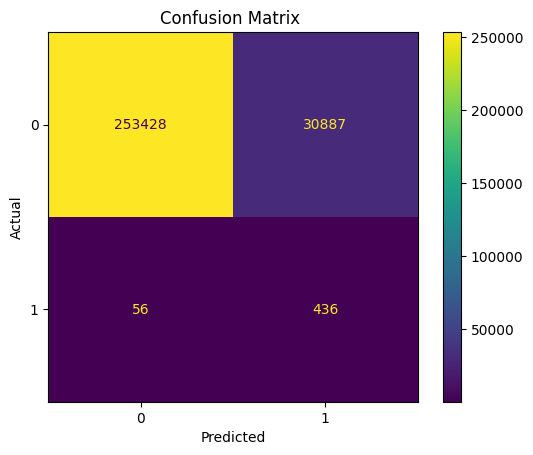

In [ ]:
print_report(y, std_outliers)

### Межквартильное отклонение

              precision    recall  f1-score   support

           0       1.00      0.92      0.96    284315
           1       0.01      0.66      0.03       492

    accuracy                           0.92    284807
   macro avg       0.51      0.79      0.49    284807
weighted avg       1.00      0.92      0.96    284807

ROC AUC score:	 0.7883156943039102


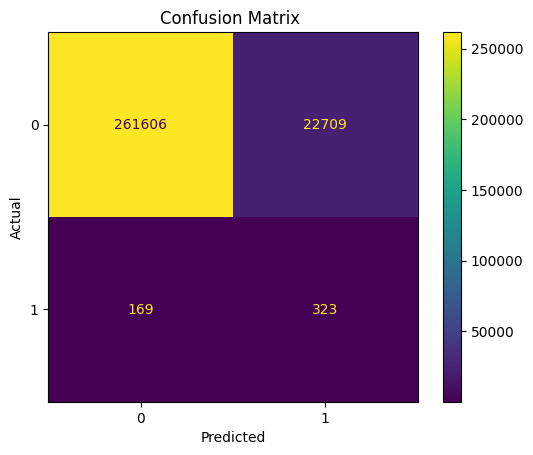

In [ ]:
print_report(y, iqr_outliers)

### Distance-based

              precision    recall  f1-score   support

           0       1.00      1.00      1.00    284315
           1       0.36      0.36      0.36       492

    accuracy                           1.00    284807
   macro avg       0.68      0.68      0.68    284807
weighted avg       1.00      1.00      1.00    284807

ROC AUC score:	 0.6813601232973446


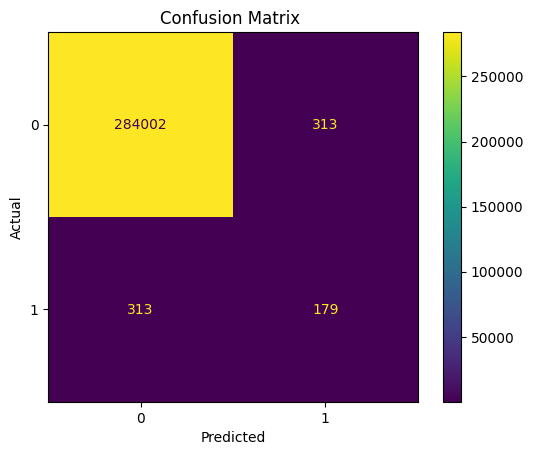

In [ ]:
print_report(y, euclidian_outliers)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00    284315
           1       0.33      0.33      0.33       492

    accuracy                           1.00    284807
   macro avg       0.67      0.67      0.67    284807
weighted avg       1.00      1.00      1.00    284807

ROC AUC score:	 0.666089841666227


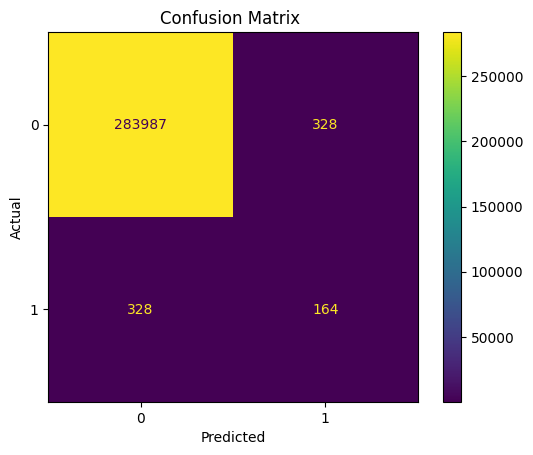

In [ ]:
print_report(y, cityblock_outliers)

### One Class SVM

              precision    recall  f1-score   support

           0       1.00      1.00      1.00    284315
           1       0.18      0.18      0.18       492

    accuracy                           1.00    284807
   macro avg       0.59      0.59      0.59    284807
weighted avg       1.00      1.00      1.00    284807

ROC AUC score:	 0.5897102957057392


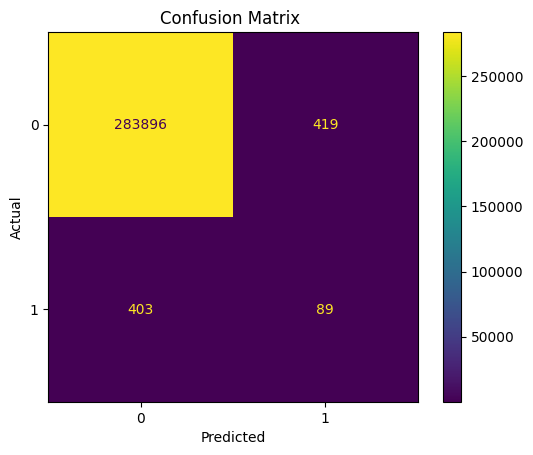

In [ ]:
print_report(y, svm_outliers)

### Isolation Forest

              precision    recall  f1-score   support

           0       1.00      1.00      1.00    284315
           1       0.33      0.33      0.33       492

    accuracy                           1.00    284807
   macro avg       0.67      0.67      0.67    284807
weighted avg       1.00      1.00      1.00    284807

ROC AUC score:	 0.6650718228908191


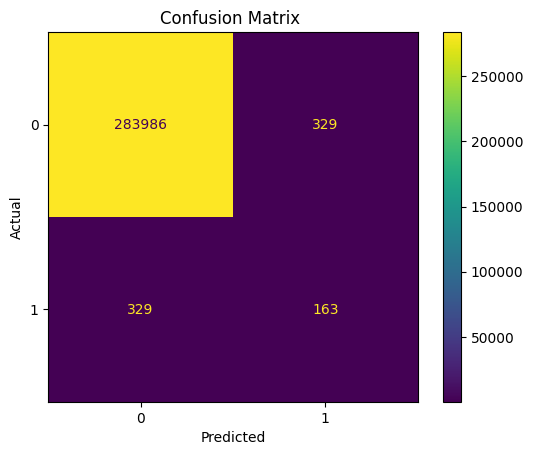

In [ ]:
print_report(y, isolation_outliers)

### DBSCAN

              precision    recall  f1-score   support

           0       1.00      0.98      0.99    284315
           1       0.06      0.73      0.11       492

    accuracy                           0.98    284807
   macro avg       0.53      0.86      0.55    284807
weighted avg       1.00      0.98      0.99    284807

ROC AUC score:	 0.85563435951965


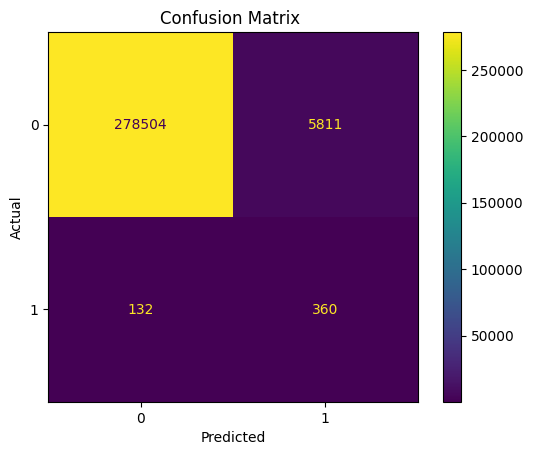

In [ ]:
print_report(y, density_outliers)

### 3 сигмы еще раз для сравнения

              precision    recall  f1-score   support

           0       1.00      0.89      0.94    284315
           1       0.01      0.89      0.03       492

    accuracy                           0.89    284807
   macro avg       0.51      0.89      0.48    284807
weighted avg       1.00      0.89      0.94    284807

ROC AUC score:	 0.8887711571486395


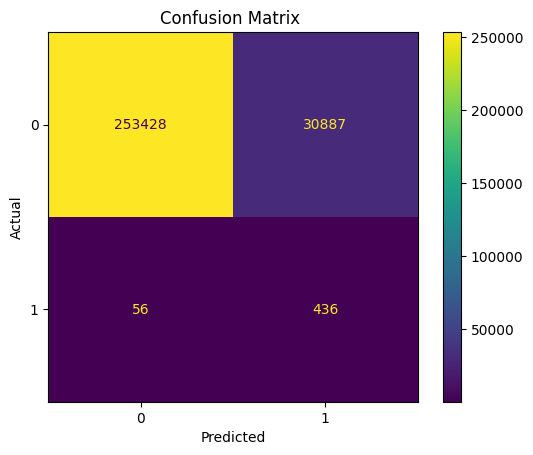

In [ ]:
print_report(y, std_outliers)

По ROC AUC лидируют 3-сигмы и DBSCAN. 3-сигмы лучше по ROC AUC и количеству правильно выявленных выбросов. Из-за большого числа ложных срабатываний, для более точной оценки, наверное, нужно знать цены ошибок первого и второго рода.

## 6. При помощи tSNE и/или UMAP, постройте сжатое представление исходных данных и проверьте, действительно ли аномалии лежат достаточно далеко от основной массы точек.

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X = scaler.fit_transform(df[df.columns.drop('Class')])
data_scaled = pd.DataFrame(X, columns=df.columns.drop('Class'))

data_scaled.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
0,0.000000,0.935192,0.766490,0.881365,0.313023,0.763439,0.267669,0.266815,0.786444,0.475312,...,0.582942,0.561184,0.522992,0.663793,0.391253,0.585122,0.394557,0.418976,0.312697,0.005824
1,0.000000,0.978542,0.770067,0.840298,0.271796,0.766120,0.262192,0.264875,0.786298,0.453981,...,0.579530,0.557840,0.480237,0.666938,0.336440,0.587290,0.446013,0.416345,0.313423,0.000105
2,0.000006,0.935217,0.753118,0.868141,0.268766,0.762329,0.281122,0.270177,0.788042,0.410603,...,0.585855,0.565477,0.546030,0.678939,0.289354,0.559515,0.402727,0.415489,0.311911,0.014739
3,0.000006,0.941878,0.765304,0.868484,0.213661,0.765647,0.275559,0.266803,0.789434,0.414999,...,0.578050,0.559734,0.510277,0.662607,0.223826,0.614245,0.389197,0.417669,0.314371,0.004807
4,0.000012,0.938617,0.776520,0.864251,0.269796,0.762975,0.263984,0.268968,0.782484,0.490950,...,0.584615,0.561327,0.547271,0.663392,0.401270,0.566343,0.507497,0.420561,0.317490,0.002724


### tSNE

<Axes: >

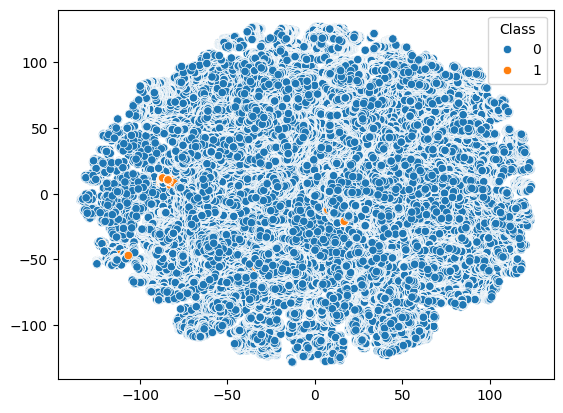

In [ ]:
from sklearn.manifold import TSNE
tsne = TSNE(n_components=2, random_state=10)
tsne_transformed = tsne.fit_transform(data_scaled)

sns.scatterplot(x=tsne_transformed[:,0], y=tsne_transformed[:,1], hue=df['Class'])

### UMAP

<Axes: >

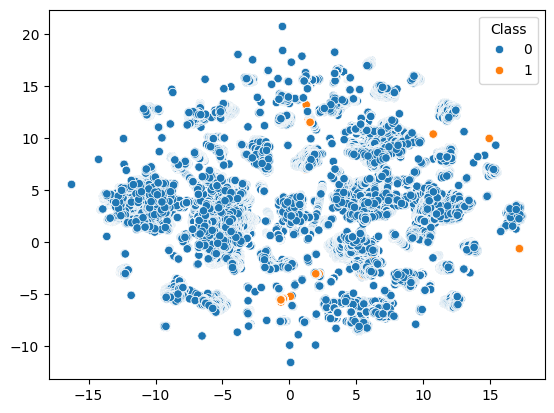

In [ ]:
from umap import UMAP
umap = UMAP()
umap_transformed = umap.fit_transform(data_scaled)

sns.scatterplot(x=umap_transformed[:,0], y=umap_transformed[:,1], hue=df['Class'])

При tSNE преобразовании точки выбросов лежат внутри облака основной массы точек. При UMAP единичные точки выбросов лежат вне облака, основная часть внутри облака. 